- Normalization: \(2(x/1023)-1\), subject to checking the model configuration and valid pixel range. the range [-1,1]

In [4]:
import sys
import csv
import time
import random
from pathlib import Path

import numpy as np
import rasterio
import torch
import matplotlib.pyplot as plt

from torch.utils.data import Dataset, DataLoader
from torch.optim import AdamW

# Project paths
ROOT = Path(r"E:\Rasengan\Cloud-Removal")
MANIFEST = ROOT / "data" / "diffcr_patches" / "manifest.csv"
CHECKPOINT_DIR = ROOT / "checkpoints"
OUTPUT_DIR = ROOT / "evaluation"

# Reproducibility
SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# Device
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

## Load and inspect the manifest

In [2]:

# Load the patch manifest
with open(MANIFEST, "r", newline="", encoding="utf-8-sig") as f:
    reader = csv.DictReader(f)
    manifest_rows = list(reader)
    manifest_columns = reader.fieldnames

print("Total patches:", f"{len(manifest_rows):,}")
print("Columns:", manifest_columns)

# Count patches by split
split_counts = {}

for row in manifest_rows:
    split = row["split"].strip().lower()
    split_counts[split] = split_counts.get(split, 0) + 1

print("\nSplit distribution:")
for split, count in sorted(split_counts.items()):
    print(f"{split}: {count:,}")

# Count unique scenes
scenes = {row["scene"] for row in manifest_rows}

print("\nUnique scenes:", len(scenes))

# Display a sample record
print("\nFirst manifest record:")
for key, value in manifest_rows[0].items():
    print(f"{key}: {value}")


Total patches: 75,551
Columns: ['scene', 'patch', 'cloudy_path', 'clear_path', 'split']

Split distribution:
test: 13,695
train: 51,414
validation: 10,442

Unique scenes: 22

First manifest record:
scene: ahemadabad1
patch: r0_c10240
cloudy_path: E:\Rasengan\Cloud-Removal\data\diffcr_patches\cloudy\ahemadabad1\r0_c10240.tif
clear_path: E:\Rasengan\Cloud-Removal\data\diffcr_patches\clear\ahemadabad1\r0_c10240.tif
split: test


## Data integrity and scene leakage

In [3]:

from collections import defaultdict

# 1. Check split names
expected_splits = {"train", "validation", "test"}
actual_splits = {row["split"].strip().lower() for row in manifest_rows}

assert actual_splits == expected_splits, (
    f"Unexpected split names: {actual_splits}"
)

# 2. Check missing cloudy and clear files
missing_cloudy = []
missing_clear = []

for row in manifest_rows:
    if not Path(row["cloudy_path"]).is_file():
        missing_cloudy.append(row["cloudy_path"])

    if not Path(row["clear_path"]).is_file():
        missing_clear.append(row["clear_path"])

# 3. Check duplicate scene-patch pairs
pair_ids = [
    (row["scene"].strip(), row["patch"].strip())
    for row in manifest_rows
]

duplicate_count = len(pair_ids) - len(set(pair_ids))

# 4. Check scene overlap between splits
scenes_by_split = defaultdict(set)

for row in manifest_rows:
    split = row["split"].strip().lower()
    scenes_by_split[split].add(row["scene"].strip())

train_scenes = scenes_by_split["train"]
val_scenes = scenes_by_split["validation"]
test_scenes = scenes_by_split["test"]

train_val_overlap = train_scenes & val_scenes
train_test_overlap = train_scenes & test_scenes
val_test_overlap = val_scenes & test_scenes

print("Missing cloudy files:", len(missing_cloudy))
print("Missing clear files:", len(missing_clear))
print("Duplicate scene-patch pairs:", duplicate_count)

print("\nUnique scenes per split:")
print("Train:", len(train_scenes))
print("Validation:", len(val_scenes))
print("Test:", len(test_scenes))

print("\nScene overlap:")
print("Train ∩ Validation:", train_val_overlap)
print("Train ∩ Test:", train_test_overlap)
print("Validation ∩ Test:", val_test_overlap)

if missing_cloudy:
    print("\nFirst missing cloudy path:", missing_cloudy[0])

if missing_clear:
    print("First missing clear path:", missing_clear[0])

assert not missing_cloudy and not missing_clear, "Missing patch files found."
assert duplicate_count == 0, "Duplicate scene-patch pairs found."
assert not train_val_overlap, "Scene leakage between train and validation."
assert not train_test_overlap, "Scene leakage between train and test."
assert not val_test_overlap, "Scene leakage between validation and test."

print("\nPASS: Data integrity checks completed.")


Missing cloudy files: 0
Missing clear files: 0
Duplicate scene-patch pairs: 0

Unique scenes per split:
Train: 15
Validation: 3
Test: 4

Scene overlap:
Train ∩ Validation: set()
Train ∩ Test: set()
Validation ∩ Test: set()

PASS: Data integrity checks completed.


## Inspect TIFF metadata and pixel ranges

In [4]:

# Select four training records
train_rows = [
    row for row in manifest_rows
    if row["split"].strip().lower() == "train"
]

sample_indices = [0, 100, 1000, 5000]

for idx in sample_indices:
    row = train_rows[idx]

    print(f"\n{'=' * 55}")
    print(f"Scene: {row['scene']} | Patch: {row['patch']}")

    for name, image_path in [
        ("Cloudy", row["cloudy_path"]),
        ("Clear", row["clear_path"]),
    ]:
        with rasterio.open(image_path) as src:
            image = src.read()

            print(f"\n{name}:")
            print("  Shape:", image.shape)
            print("  Data type:", src.dtypes)
            print("  CRS:", src.crs)
            print("  Dimensions:", src.width, "x", src.height)
            print("  Band minima:", image.min(axis=(1, 2)).tolist())
            print("  Band maxima:", image.max(axis=(1, 2)).tolist())
            print("  Band means:", np.round(
                image.mean(axis=(1, 2)), 2
            ).tolist())



Scene: chennai1 | Patch: r0_c10240

Cloudy:
  Shape: (3, 256, 256)
  Data type: ('uint16', 'uint16', 'uint16')
  CRS: EPSG:32644
  Dimensions: 256 x 256
  Band minima: [115, 92, 160]
  Band maxima: [375, 364, 413]
  Band means: [215.74, 203.68, 269.72]

Clear:
  Shape: (3, 256, 256)
  Data type: ('uint16', 'uint16', 'uint16')
  CRS: EPSG:32644
  Dimensions: 256 x 256
  Band minima: [104, 88, 114]
  Band maxima: [199, 257, 335]
  Band means: [133.09, 141.62, 235.48]

Scene: chennai1 | Patch: r10240_c8704

Cloudy:
  Shape: (3, 256, 256)
  Data type: ('uint16', 'uint16', 'uint16')
  CRS: EPSG:32644
  Dimensions: 256 x 256
  Band minima: [129, 109, 231]
  Band maxima: [466, 479, 536]
  Band means: [268.8, 268.16, 366.48]

Clear:
  Shape: (3, 256, 256)
  Data type: ('uint16', 'uint16', 'uint16')
  CRS: EPSG:32644
  Dimensions: 256 x 256
  Band minima: [86, 66, 98]
  Band maxima: [193, 225, 332]
  Band means: [111.86, 111.47, 205.14]

Scene: chennai1 | Patch: r14080_c9216

Cloudy:
  Shape: 

## Analyze pixel distributions and choose normalization

Sampled 100 paired patches
Band order: B2 Green, B3 Red, B4 NIR

B2 Green
Cloudy percentiles [1, 50, 99]: [138. 386. 910.]
Clear percentiles  [1, 50, 99]: [ 34.  99. 607.]
Cloudy mean: 444.28 | Clear mean: 113.18

B3 Red
Cloudy percentiles [1, 50, 99]: [115. 381. 919.]
Clear percentiles  [1, 50, 99]: [ 24.  96. 629.]
Cloudy mean: 438.65 | Clear mean: 112.48

B4 NIR
Cloudy percentiles [1, 50, 99]: [216. 446. 897.]
Clear percentiles  [1, 50, 99]: [ 48. 187. 625.]
Cloudy mean: 490.77 | Clear mean: 197.14


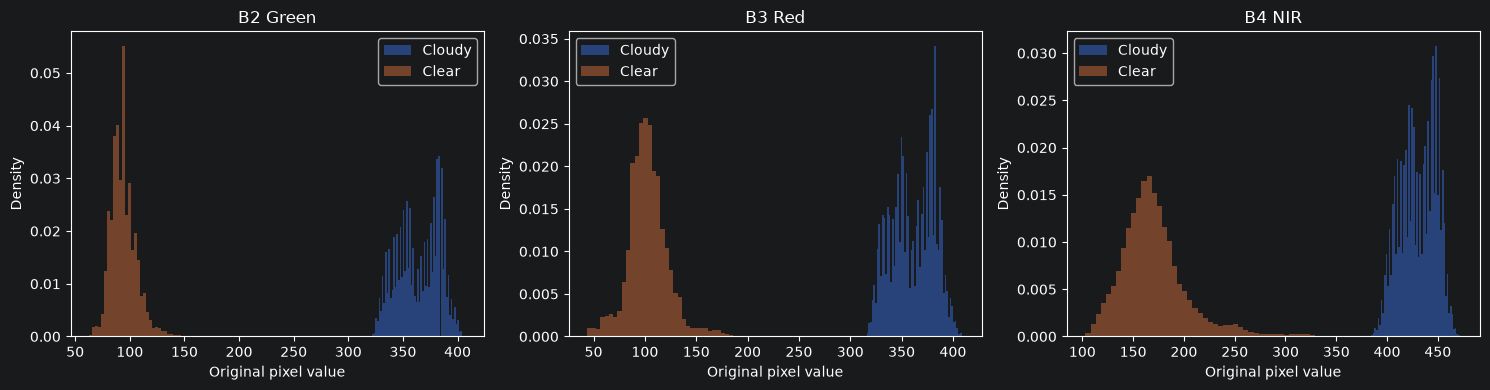

In [5]:

# Sample up to 100 training pairs
rng = np.random.default_rng(SEED)
sample_count = min(100, len(train_rows))
selected_indices = rng.choice(
    len(train_rows), size=sample_count, replace=False
)

cloudy_values = [[], [], []]
clear_values = [[], [], []]

for idx in selected_indices:
    row = train_rows[int(idx)]

    with rasterio.open(row["cloudy_path"]) as src:
        cloudy = src.read().astype(np.float32)

    with rasterio.open(row["clear_path"]) as src:
        clear = src.read().astype(np.float32)

    for band in range(3):
        cloudy_values[band].append(cloudy[band].ravel())
        clear_values[band].append(clear[band].ravel())

print(f"Sampled {sample_count} paired patches")
print("Band order: B2 Green, B3 Red, B4 NIR")

for band, band_name in enumerate(["B2 Green", "B3 Red", "B4 NIR"]):
    cloudy_band = np.concatenate(cloudy_values[band])
    clear_band = np.concatenate(clear_values[band])

    print(f"\n{band_name}")
    print(
        "Cloudy percentiles [1, 50, 99]:",
        np.round(np.percentile(cloudy_band, [1, 50, 99]), 2)
    )
    print(
        "Clear percentiles  [1, 50, 99]:",
        np.round(np.percentile(clear_band, [1, 50, 99]), 2)
    )
    print(
        "Cloudy mean:", round(float(cloudy_band.mean()), 2),
        "| Clear mean:", round(float(clear_band.mean()), 2)
    )

# Visualize the distributions
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for band, band_name in enumerate(["B2 Green", "B3 Red", "B4 NIR"]):
    axes[band].hist(
        cloudy_values[band][0],
        bins=60, alpha=0.5, density=True, label="Cloudy"
    )
    axes[band].hist(
        clear_values[band][0],
        bins=60, alpha=0.5, density=True, label="Clear"
    )
    axes[band].set_title(band_name)
    axes[band].set_xlabel("Original pixel value")
    axes[band].set_ylabel("Density")
    axes[band].legend()

plt.tight_layout()
plt.show()


## Verify the dataset's raster metadata

In [6]:
# Inspect raster metadata for one training pair
row = train_rows[0]

for name, image_path in [
    ("Cloudy", row["cloudy_path"]),
    ("Clear", row["clear_path"]),
]:
    with rasterio.open(image_path) as src:
        print(f"\n{name} image")
        print("File:", image_path)
        print("Band count:", src.count)
        print("Data types:", src.dtypes)
        print("Scales:", src.scales)
        print("Offsets:", src.offsets)
        print("Nodata:", src.nodata)
        print("Dataset tags:", src.tags())

        for band_idx in range(1, src.count + 1):
            print(
                f"Band {band_idx} tags:",
                src.tags(band_idx)
            )


Cloudy image
File: E:\Rasengan\Cloud-Removal\data\diffcr_patches\cloudy\chennai1\r0_c10240.tif
Band count: 3
Data types: ('uint16', 'uint16', 'uint16')
Scales: (1.0, 1.0, 1.0)
Offsets: (0.0, 0.0, 0.0)
Nodata: None
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 2 tags: {}
Band 3 tags: {}

Clear image
File: E:\Rasengan\Cloud-Removal\data\diffcr_patches\clear\chennai1\r0_c10240.tif
Band count: 3
Data types: ('uint16', 'uint16', 'uint16')
Scales: (1.0, 1.0, 1.0)
Offsets: (0.0, 0.0, 0.0)
Nodata: None
Dataset tags: {'AREA_OR_POINT': 'Area'}
Band 1 tags: {}
Band 2 tags: {}
Band 3 tags: {}


## Import and inspect the model components

In [5]:

from src.model import DiffCRModel
from src.diffusion import Diffusion
from src.sampler import DiffusionSampler

print("Model, diffusion, and sampler imported successfully.")

model = DiffCRModel().to(DEVICE)
diffusion = Diffusion(device=DEVICE)
sampler = DiffusionSampler(diffusion)

print("\nModel:", type(model).__name__)
print("Diffusion:", type(diffusion).__name__)
print("Sampler:", type(sampler).__name__)

print("\nModel parameters:", f"{sum(p.numel() for p in model.parameters()):,}")
print("Trainable parameters:", f"{sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

print("\nDiffusion timesteps:", diffusion.timesteps)
print("Alpha bars shape:", tuple(diffusion.alpha_bars.shape))
print("Model device:", next(model.parameters()).device)


Model, diffusion, and sampler imported successfully.

Model: DiffCRModel
Diffusion: Diffusion
Sampler: DiffusionSampler

Model parameters: 6,019,907
Trainable parameters: 6,019,907

Diffusion timesteps: 1000
Alpha bars shape: (1000,)
Model device: cuda:0


## verify model input and output shapes

In [8]:

# Synthetic inputs: batch=1, channels=3, height=256, width=256
model.eval()

test_cloudy = torch.randn(1, 3, 256, 256, device=DEVICE)
test_noisy = torch.randn(1, 3, 256, 256, device=DEVICE)
test_timesteps = torch.tensor([500], dtype=torch.long, device=DEVICE)

test_model_input = torch.cat([test_cloudy, test_noisy], dim=1)

print("Cloudy shape:", tuple(test_cloudy.shape))
print("Noisy image shape:", tuple(test_noisy.shape))
print("Concatenated input shape:", tuple(test_model_input.shape))

with torch.inference_mode():
    test_output = model(test_model_input, test_timesteps)

print("Model output shape:", tuple(test_output.shape))
print("Output finite:", torch.isfinite(test_output).all().item())
print("Output min/max:", test_output.min().item(), test_output.max().item())

assert test_model_input.shape == (1, 6, 256, 256)
assert test_output.shape == (1, 3, 256, 256)
assert torch.isfinite(test_output).all()

print("\nPASS: Model forward pass.")


Cloudy shape: (1, 3, 256, 256)
Noisy image shape: (1, 3, 256, 256)
Concatenated input shape: (1, 6, 256, 256)
Model output shape: (1, 3, 256, 256)
Output finite: True
Output min/max: -2.3009250164031982 2.695720911026001

PASS: Model forward pass.


In [9]:
import inspect
print("Diffusion.training_loss implementation:\n")
print(inspect.getsource(Diffusion.training_loss))

Diffusion.training_loss implementation:

    def training_loss(self, model, cloudy, clear):
        if cloudy.shape != clear.shape:
            raise ValueError(
                f"cloudy and clear must have the same shape; "
                f"got {cloudy.shape} and {clear.shape}"
            )

        batch_size = clear.shape[0]

        timesteps = torch.randint(
            0,
            self.timesteps,
            (batch_size,),
            device=clear.device,
            dtype=torch.long,
        )

        noise = torch.randn_like(clear)

        noisy_clear = self.q_sample(
            clear, timesteps, noise=noise
        )

        model_input = torch.cat(
            [cloudy, noisy_clear], dim=1
        )

        predicted_clear = model(model_input, timesteps)

        loss = F.l1_loss(predicted_clear, clear)

        return loss, {
            "timesteps": timesteps,
            "noisy_clear": noisy_clear,
            "predicted_clear": predicted_clear,
        }



## Test one optimization step

In [12]:
from src.train import  SatellitePatchDataset
# Load one real batch
train_dataset = SatellitePatchDataset(MANIFEST, "train")

train_loader = DataLoader(
    train_dataset,
    batch_size=4,
    shuffle=True,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

cloudy, clear = next(iter(train_loader))
cloudy = cloudy.to(DEVICE)
clear = clear.to(DEVICE)

print("Cloudy batch:", tuple(cloudy.shape))
print("Clear batch:", tuple(clear.shape))

# One forward + backward + optimizer update
model.train()
optimizer = AdamW(model.parameters(), lr=1e-4, weight_decay=1e-4)
optimizer.zero_grad(set_to_none=True)

loss, _ = diffusion.training_loss(model, cloudy, clear)

assert torch.isfinite(loss).item(), f"Invalid loss: {loss.item()}"

loss.backward()

gradients = [
    p.grad for p in model.parameters()
    if p.grad is not None
]

assert gradients, "No gradients were produced."
assert all(torch.isfinite(g).all().item() for g in gradients), (
    "NaN or Inf found in gradients."
)

torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
optimizer.step()

print(f"Initial batch loss: {loss.item():.6f}")

train: 51,414 patches
Cloudy batch: (4, 3, 256, 256)
Clear batch: (4, 3, 256, 256)
Initial batch loss: 0.921512


In [13]:
import time
import torch

model.train()
batch_times = []
batch_losses = []

for i, (cloudy, clear) in enumerate(train_loader):
    if i >= 20:
        break

    start = time.perf_counter()

    cloudy = cloudy.to(DEVICE)
    clear = clear.to(DEVICE)

    optimizer.zero_grad(set_to_none=True)

    with torch.autocast(
        device_type="cuda",
        dtype=torch.float16,
        enabled=(DEVICE.type == "cuda")
    ):
        loss, _ = diffusion.training_loss(model, cloudy, clear)

    if not torch.isfinite(loss):
        raise RuntimeError(f"Non-finite loss at benchmark batch {i}")

    loss.backward()
    torch.nn.utils.clip_grad_norm_(model.parameters(), max_norm=1.0)
    optimizer.step()

    if DEVICE.type == "cuda":
        torch.cuda.synchronize()

    batch_times.append(time.perf_counter() - start)
    batch_losses.append(loss.item())

avg_time = sum(batch_times) / len(batch_times)

print(f"Benchmark batches: {len(batch_times)}")
print(f"Average batch time: {avg_time:.2f} seconds")
print(f"Average loss: {sum(batch_losses) / len(batch_losses):.6f}")
print(f"Estimated training time per epoch: {avg_time * len(train_loader) / 3600:.2f} hours")

Benchmark batches: 20
Average batch time: 0.47 seconds
Average loss: 0.594062
Estimated training time per epoch: 1.66 hours


In [14]:
import time
import torch
from torch.utils.data import DataLoader

CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)

val_dataset = SatellitePatchDataset(MANIFEST, "validation")
val_loader = DataLoader(
    val_dataset,
    batch_size=4,
    shuffle=False,
    num_workers=0,
    pin_memory=(DEVICE.type == "cuda"),
)

EPOCHS = 10
LR = 1e-4
BEST_PATH = CHECKPOINT_DIR / "best_model.pth"
LATEST_PATH = CHECKPOINT_DIR / "latest_checkpoint.pth"

optimizer = AdamW(model.parameters(), lr=LR, weight_decay=1e-4)
scaler = torch.amp.GradScaler("cuda", enabled=(DEVICE.type == "cuda"))

start_epoch = 0
best_val_loss = float("inf")

if LATEST_PATH.exists():
    checkpoint = torch.load(
        LATEST_PATH, map_location=DEVICE, weights_only=False
    )
    model.load_state_dict(checkpoint["model"])
    optimizer.load_state_dict(checkpoint["optimizer"])
    scaler.load_state_dict(checkpoint["scaler"])
    start_epoch = checkpoint["epoch"] + 1
    best_val_loss = checkpoint["best_val_loss"]
    print(f"Resuming from epoch {start_epoch + 1}")

for epoch in range(start_epoch, EPOCHS):
    epoch_start = time.perf_counter()
    model.train()
    train_total = 0.0
    train_count = 0

    for batch_idx, (cloudy, clear) in enumerate(train_loader):
        cloudy = cloudy.to(DEVICE, non_blocking=True)
        clear = clear.to(DEVICE, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.autocast(
            device_type=DEVICE.type,
            dtype=torch.float16,
            enabled=(DEVICE.type == "cuda"),
        ):
            loss, _ = diffusion.training_loss(model, cloudy, clear)

        if not torch.isfinite(loss):
            raise RuntimeError(
                f"Non-finite training loss at epoch {epoch + 1}, "
                f"batch {batch_idx + 1}"
            )

        scaler.scale(loss).backward()
        scaler.unscale_(optimizer)
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        scaler.step(optimizer)
        scaler.update()

        batch_size = cloudy.size(0)
        train_total += loss.item() * batch_size
        train_count += batch_size

        if (batch_idx + 1) % 500 == 0:
            print(
                f"Epoch {epoch + 1}/{EPOCHS} | "
                f"Batch {batch_idx + 1}/{len(train_loader)} | "
                f"Loss {loss.item():.4f}"
            )

    train_loss = train_total / train_count

    model.eval()
    val_total = 0.0
    val_count = 0

    with torch.no_grad():
        for cloudy, clear in val_loader:
            cloudy = cloudy.to(DEVICE, non_blocking=True)
            clear = clear.to(DEVICE, non_blocking=True)

            with torch.autocast(
                device_type=DEVICE.type,
                dtype=torch.float16,
                enabled=(DEVICE.type == "cuda"),
            ):
                val_loss, _ = diffusion.training_loss(
                    model, cloudy, clear
                )

            batch_size = cloudy.size(0)
            val_total += val_loss.item() * batch_size
            val_count += batch_size

    val_loss = val_total / val_count

    if val_loss < best_val_loss:
        best_val_loss = val_loss
        torch.save(
            {
                "model": model.state_dict(),
                "epoch": epoch,
                "best_val_loss": best_val_loss,
            },
            BEST_PATH,
        )

    torch.save(
        {
            "model": model.state_dict(),
            "optimizer": optimizer.state_dict(),
            "scaler": scaler.state_dict(),
            "epoch": epoch,
            "best_val_loss": best_val_loss,
        },
        LATEST_PATH,
    )

    elapsed = (time.perf_counter() - epoch_start) / 60

    print(
        f"\nEpoch {epoch + 1}/{EPOCHS} complete | "
        f"Train loss: {train_loss:.5f} | "
        f"Val loss: {val_loss:.5f} | "
        f"Best val: {best_val_loss:.5f} | "
        f"Time: {elapsed:.1f} min\n"
    )

print("Training finished.")
print("Best model:", BEST_PATH)
print("Latest checkpoint:", LATEST_PATH)

validation: 10,442 patches
Epoch 1/10 | Batch 500/12854 | Loss 0.0825
Epoch 1/10 | Batch 1000/12854 | Loss 0.0637
Epoch 1/10 | Batch 1500/12854 | Loss 0.0534
Epoch 1/10 | Batch 2000/12854 | Loss 0.0664
Epoch 1/10 | Batch 2500/12854 | Loss 0.0910
Epoch 1/10 | Batch 3000/12854 | Loss 0.1148
Epoch 1/10 | Batch 3500/12854 | Loss 0.0305
Epoch 1/10 | Batch 4000/12854 | Loss 0.0558
Epoch 1/10 | Batch 4500/12854 | Loss 0.1987
Epoch 1/10 | Batch 5000/12854 | Loss 0.0862
Epoch 1/10 | Batch 5500/12854 | Loss 0.0366
Epoch 1/10 | Batch 6000/12854 | Loss 0.0547
Epoch 1/10 | Batch 6500/12854 | Loss 0.0423
Epoch 1/10 | Batch 7000/12854 | Loss 0.1004
Epoch 1/10 | Batch 7500/12854 | Loss 0.0387
Epoch 1/10 | Batch 8000/12854 | Loss 0.0324
Epoch 1/10 | Batch 8500/12854 | Loss 0.0460
Epoch 1/10 | Batch 9000/12854 | Loss 0.0320
Epoch 1/10 | Batch 9500/12854 | Loss 0.0445
Epoch 1/10 | Batch 10000/12854 | Loss 0.0328
Epoch 1/10 | Batch 10500/12854 | Loss 0.0513
Epoch 1/10 | Batch 11000/12854 | Loss 0.0452
Epo

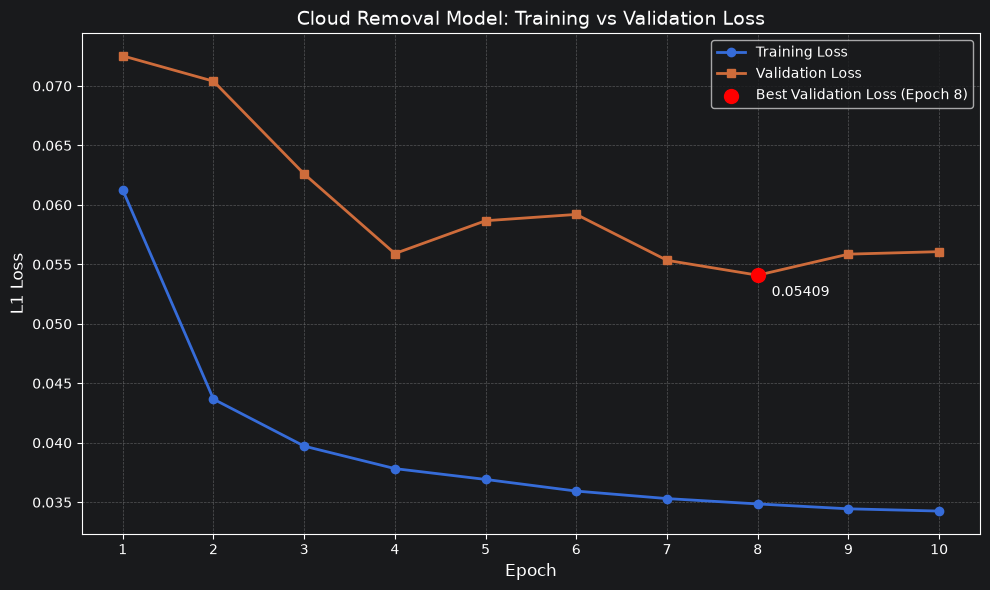

In [15]:
import matplotlib.pyplot as plt

epochs = list(range(1, 11))

train_losses = [
    0.06125, 0.04367, 0.03972, 0.03783, 0.03692,
    0.03594, 0.03531, 0.03486, 0.03445, 0.03426
]

val_losses = [
    0.07253, 0.07040, 0.06260, 0.05591, 0.05867,
    0.05920, 0.05534, 0.05409, 0.05586, 0.05607
]

plt.figure(figsize=(10, 6))

plt.plot(
    epochs, train_losses,
    marker='o', linewidth=2, markersize=6,
    label='Training Loss'
)

plt.plot(
    epochs, val_losses,
    marker='s', linewidth=2, markersize=6,
    label='Validation Loss'
)

best_epoch = val_losses.index(min(val_losses)) + 1

plt.scatter(
    best_epoch, min(val_losses),
    color='red', s=100, zorder=5,
    label=f'Best Validation Loss (Epoch {best_epoch})'
)

plt.annotate(
    f'{min(val_losses):.5f}',
    (best_epoch, min(val_losses)),
    xytext=(10, -15),
    textcoords='offset points'
)

plt.xlabel('Epoch', fontsize=12)
plt.ylabel('L1 Loss', fontsize=12)
plt.title('Cloud Removal Model: Training vs Validation Loss', fontsize=14)

plt.xticks(epochs)
plt.grid(True, linestyle='--', alpha=0.4)
plt.legend()
plt.tight_layout()
plt.show()